## Ordinal Logistic Regression in Practice: Payment History

---

### 1. The Business Problem

A bank's **Credit team** rates every client's payment history as **Bueno**, **Regular** or **Malo**, and wants to know: **which client characteristics are associated with a worse payment history?**

The response, `historial_pagos`, has 3 categories **with a natural order**: Bueno < Regular < Malo. We have two simpler options, and both lose something:
- **Use the nominal model from Part 1.** It ignores the order and needs more parameters.
- **Code the categories as 1, 2, 3 and use linear regression.** It assumes the distance between Bueno and Regular equals the distance between Regular and Malo, which is rarely true.

The **ordinal logistic model** (proportional odds) uses the order and keeps a **single coefficient per predictor**. It models cumulative probabilities, one equation per cut between categories:

`logit[ P(Y ≤ Bueno) ] = α₁ − xᵀβ`          `logit[ P(Y ≤ Regular) ] = α₂ − xᵀβ`

- Both equations share the **same β**; only the **thresholds** α₁ < α₂ change. That shared β is the "proportional odds" assumption.
- A **positive β pushes toward the higher categories**, that is, toward a *worse* history.

With 4 predictors (5 columns, because `estado_civil` becomes 2 dummies) and 3 categories we expect 5 slopes + 2 thresholds = **7 parameters**, against 12 in the nominal model.

### 2. The Data

Same file as in Part 1: `clientes_multicategoria.csv`, one row per client.

| Column | Type | Description |
|---|---|---|
| `id_cliente` | ID | Client identifier |
| `ingreso_mensual` | Numeric | Monthly income, in **thousands** of MXN |
| `edad_cliente` | Numeric | Client age |
| `score_buro` | Numeric | Credit bureau score |
| `estado_civil` | Categorical | Casado (**reference**) / Soltero / Divorciado |
| `historial_pagos` | **Target** (ordinal) | Bueno < Regular < Malo |
| `tipo_producto` | Another response (nominal) | Used in Part 1. **It is not a predictor here.** |

The model uses the same four predictors as Part 1.

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.miscmodels.ordinal_model import OrderedModel
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, roc_auc_score

plt.rcParams['figure.figsize'] = (8, 5)

df = pd.read_csv('clientes_multicategoria.csv')
df.head()

,id_cliente,ingreso_mensual,edad_cliente,score_buro,estado_civil,tipo_producto,historial_pagos
0,CL-0001,8.0,53,756,Casado,Mortgage,Bueno
1,CL-0002,20.5,52,619,Divorciado,Personal loan,Malo
2,CL-0003,8.0,39,721,Casado,Personal loan,Regular
3,CL-0004,18.0,21,714,Divorciado,Personal loan,Regular
4,CL-0005,38.9,58,638,Soltero,Card,Regular


### 3. Data Quality Review

In [48]:
print('Shape:', df.shape)
print('Missing values:', df.isna().sum().sum())
print('Duplicate IDs:', df['id_cliente'].duplicated().sum())
df.describe().round(1).T

Shape: (1000, 7)
Missing values: 0
Duplicate IDs: 0


,count,mean,std,min,25%,50%,75%,max
ingreso_mensual,1000.0,29.9,14.9,8.0,19.1,27.4,38.9,98.9
edad_cliente,1000.0,43.3,12.9,21.0,32.0,43.0,54.0,65.0
score_buro,1000.0,682.5,54.4,450.0,645.0,684.0,720.0,850.0


Clean, as in Part 1: no missing values, no duplicate IDs, sensible ranges.

### 4. Setting Up the Categories

Here the order of the list **is the order of the response**: Bueno < Regular < Malo. For the ordinal model the response must be an *ordered* categorical.

In [49]:
history_order = ['Bueno', 'Regular', 'Malo']                    # lowest category first
df['historial_pagos'] = pd.Categorical(df['historial_pagos'], categories=history_order, ordered=True)
df['estado_civil'] = pd.Categorical(df['estado_civil'], categories=['Casado', 'Soltero', 'Divorciado'])

### 5. Exploring the Response

historial_pagos
Bueno      0.543
Regular    0.293
Malo       0.164
Name: proportion, dtype: float64


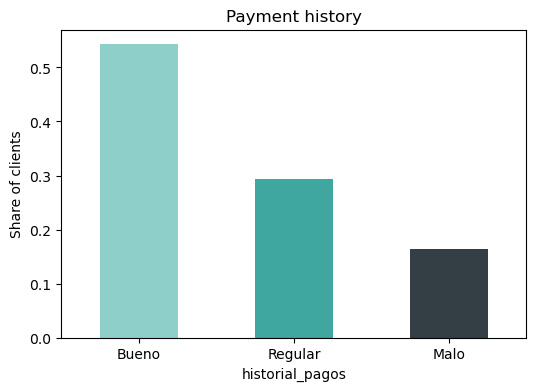

In [50]:
shares = df['historial_pagos'].value_counts(normalize=True).reindex(history_order)
print(shares.round(3))

ax = shares.plot(kind='bar', color=['#8FCFC9', '#3FA7A0', '#333F44'], rot=0, figsize=(6, 4))
ax.set_ylabel('Share of clients')
ax.set_title('Payment history')
plt.show()

**Interpretation:** Bueno 54.3%, Regular 29.3%, Malo 16.4%. Malo is the rarest category. A model that always predicted Bueno would be right 54.3% of the time — the **baseline** to beat. (The colors go from light to dark because the categories are ordered.)

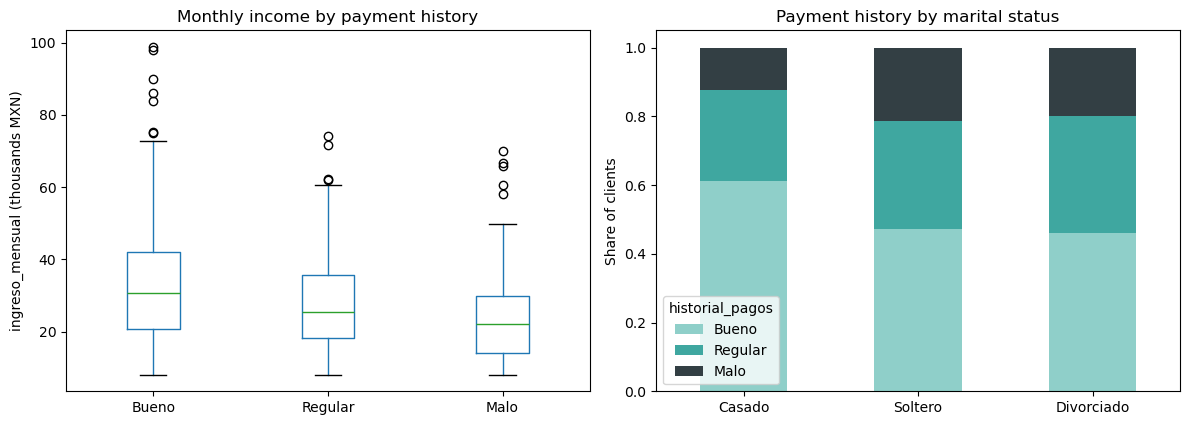

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

df.boxplot(column='ingreso_mensual', by='historial_pagos', ax=axes[0], grid=False)
axes[0].set_title('Monthly income by payment history')
axes[0].set_xlabel('')
axes[0].set_ylabel('ingreso_mensual (thousands MXN)')

mix = pd.crosstab(df['estado_civil'], df['historial_pagos'], normalize='index')[history_order]
mix.plot(kind='bar', stacked=True, ax=axes[1], color=['#8FCFC9', '#3FA7A0', '#333F44'], rot=0)
axes[1].set_title('Payment history by marital status')
axes[1].set_xlabel('')
axes[1].set_ylabel('Share of clients')

plt.suptitle('')
plt.tight_layout()
plt.show()

**Interpretation:**
- **Income falls as the history gets worse:** about $33k per month for Bueno, $27.5k for Regular and $23.7k for Malo.
- **Marital status:** Malo is less common among Married clients (12%) than among Single (21%) or Divorced clients (20%).

### 6. Preparing Y and X

In [62]:
y = df['historial_pagos']                                  # ordered categorical

# X: only the four predictors. `tipo_producto` is another response, so it stays out.
dummies = pd.get_dummies(df[['estado_civil']], drop_first=True, dtype=float)    # Casado is dropped = reference
X = pd.concat([df[['ingreso_mensual', 'edad_cliente', 'score_buro']], dummies], axis=1)
# NO add_constant here: in the ordinal model the thresholds play the role of the intercept

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f'Train: {len(X_train)}   Test: {len(X_test)}')
X_train.head()

Train: 800   Test: 200


,ingreso_mensual,edad_cliente,score_buro,estado_civil_Soltero,estado_civil_Divorciado
997,13.4,38,692,0.0,1.0
951,11.1,32,689,0.0,0.0
313,11.5,30,636,1.0,0.0
235,55.9,57,711,1.0,0.0
347,18.6,49,708,1.0,0.0


Unlike the nominal model, **no constant is added**: the thresholds take that job, and adding one raises an error.

### 7. Fitting the Model

In [63]:
model = OrderedModel(y_train, X_train, distr='logit')
result = model.fit(method='bfgs', disp=False)
print(result.summary())

                             OrderedModel Results                             
Dep. Variable:        historial_pagos   Log-Likelihood:                -674.43
Model:                   OrderedModel   AIC:                             1363.
Method:            Maximum Likelihood   BIC:                             1396.
Date:                Thu, 15 Oct 2026                                         
Time:                        18:46:54                                         
No. Observations:                 800                                         
Df Residuals:                     793                                         
Df Model:                           5                                         
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
ingreso_mensual            -0.0462      0.006     -8.181      0.000      -0.057      -0.035
edad_cliente 

**How to read the summary:** the first five rows are the **slopes**, one per predictor column. The last two rows are the **thresholds**, labelled by the categories they separate. Careful: in the summary the second threshold is not α₂ itself but the (log of the) *gap* between α₂ and α₁, because that is how the optimizer keeps the thresholds in order. To see the real thresholds, use `transform_threshold_params`.

In [54]:
k = X_train.shape[1]
print(f'{k} slopes + {len(result.params) - k} thresholds = {len(result.params)} parameters')

thresholds = model.transform_threshold_params(result.params)[1:-1]     # drop the -inf and +inf ends
print('Thresholds (alpha1, alpha2):', thresholds.round(2))

5 slopes + 2 thresholds = 7 parameters
Thresholds (alpha1, alpha2): [-13.13 -11.31]


7 parameters, exactly as predicted in Section 1. The thresholds are not interpreted on their own — they only position the categories on the underlying scale (their size here is large because the predictors are not centered). The slopes are what we read.

### 8. Interpreting the Coefficients

In [55]:
betas = result.params.iloc[:k]
pvalues = result.pvalues.iloc[:k]

pd.DataFrame({'log-odds (β)': betas, 'odds ratio exp(β)': np.exp(betas), 'p-value': pvalues}).round(4)

,log-odds (β),odds ratio exp(β),p-value
ingreso_mensual,-0.0462,0.9549,0.0000
edad_cliente,-0.0211,0.9791,0.0003
score_buro,-0.0168,0.9834,0.0000
estado_civil_Soltero,0.7733,2.1669,0.0000
estado_civil_Divorciado,0.7577,2.1333,0.0005


**Significance** works as in the binary model: H₀: β = 0 against H₁: β ≠ 0, tested with the Wald z-test. All five predictors are significant at 5%.

**Reading template:** *for each extra unit of X, the odds of a worse payment history (instead of a better one) are multiplied by exp(β).* This is **one number per predictor, valid at every cut**: the odds of Regular-or-Malo versus Bueno, and of Malo versus Bueno-or-Regular, are multiplied by the same factor.

In [56]:
b = betas['ingreso_mensual']
print(f'ingreso_mensual: +$1,000 multiplies the odds of a worse history by {np.exp(b):.3f};  +$10,000 by {np.exp(10 * b):.3f}')
for name in ['estado_civil_Soltero', 'estado_civil_Divorciado']:
    b = betas[name]
    print(f'{name}: multiplies the odds of a worse history by {np.exp(b):.3f}  ({(np.exp(b) - 1) * 100:+.0f}%)')

ingreso_mensual: +$1,000 multiplies the odds of a worse history by 0.955;  +$10,000 by 0.630
estado_civil_Soltero: multiplies the odds of a worse history by 2.167  (+117%)
estado_civil_Divorciado: multiplies the odds of a worse history by 2.133  (+113%)


**Numeric predictor — `ingreso_mensual`** (β < 0, so it pushes toward a *better* history): each extra $1,000 of monthly income multiplies the odds of a worse payment history by **0.955** (−4.5%); over +$10,000 of income, by 0.63.

**Categorical predictors** (reference: Casado): Single clients have **2.17×** the odds of a worse history than Married clients (+117%), and Divorced clients have **2.13×**, both holding the other predictors fixed.

Notice the contrast with Part 1: there, each predictor had one coefficient *per column* and the same variable could point in opposite directions. Here each predictor has a single coefficient, so its direction is the same everywhere along the scale.

## 9. Checking the Proportional-Odds Assumption

The model assumes one shared β for both cuts. A simple, informal check: fit a separate binary logit for each cut and see whether the coefficients are similar. (statsmodels does not include a formal test such as Brant's.)

In [57]:
codes = y_train.cat.codes
X_const = sm.add_constant(X_train)

checks = {}
for cut, label in [(0, 'Bueno vs. Regular/Malo'), (1, 'Bueno/Regular vs. Malo')]:
    m = sm.Logit((codes > cut).astype(int), X_const).fit(disp=False)
    checks[label] = m.params.drop('const')
checks['Ordinal model (shared β)'] = betas

pd.DataFrame(checks).round(3)

,Bueno vs. Regular/Malo,Bueno/Regular vs. Malo,Ordinal model (shared β)
ingreso_mensual,-0.046,-0.048,-0.046
edad_cliente,-0.024,-0.011,-0.021
score_buro,-0.017,-0.016,-0.017
estado_civil_Soltero,0.761,0.824,0.773
estado_civil_Divorciado,0.789,0.684,0.758


**Interpretation:** the coefficients are close at both cuts — for example `ingreso_mensual` −0.046 and −0.048, `score_buro` −0.017 and −0.016 — and close to the shared β of the ordinal model. The largest gap is in `edad_cliente` (−0.024 vs. −0.011), but its effect is small. A single shared β is reasonable here. If the coefficients differed a lot, the nominal model would be the safer choice.

## 10. Checking Performance

In [58]:
proba = np.asarray(result.predict(X_test))          # one probability per category; each row adds up to 1
pd.DataFrame(proba[:5], columns=history_order).round(3)

,Bueno,Regular,Malo
0,0.286,0.427,0.287
1,0.578,0.316,0.105
2,0.504,0.359,0.137
3,0.900,0.083,0.018
4,0.306,0.426,0.267


As in the nominal model, there is **one probability per category**. The predicted category is the one with the highest probability.

In [59]:
pred = proba.argmax(axis=1)
true = y_test.cat.codes.values

cm = confusion_matrix(true, pred)
print(pd.DataFrame(cm, index=[f'Actual: {h}' for h in history_order],
                   columns=[f'Pred: {h}' for h in history_order]))
print()
print(classification_report(true, pred, target_names=history_order))
baseline = pd.Series(true).value_counts(normalize=True).max()

baseline = y_test.value_counts(normalize=True).max()
print(f'Accuracy: {accuracy_score(true, pred):.3f}   (baseline, always Bueno: {baseline:.3f})')
print(f'Macro AUC (one-vs-rest): {roc_auc_score(true, proba, multi_class="ovr"):.3f}')
print(f'McFadden pseudo R2: {result.prsquared:.3f}')

                 Pred: Bueno  Pred: Regular  Pred: Malo
Actual: Bueno             89             18           1
Actual: Regular           38             18           3
Actual: Malo              13             12           8

              precision    recall  f1-score   support

       Bueno       0.64      0.82      0.72       108
     Regular       0.38      0.31      0.34        59
        Malo       0.67      0.24      0.36        33

    accuracy                           0.57       200
   macro avg       0.56      0.46      0.47       200
weighted avg       0.56      0.57      0.55       200

Accuracy: 0.575   (baseline, always Bueno: 0.540)
Macro AUC (one-vs-rest): 0.696
McFadden pseudo R2: 0.146


**Interpretation:**

**Interpretation:**

- **Overall.** Accuracy is 0.575 against a baseline of 0.540, so the model beats "always Bueno" by only 3.5 points. A macro AUC of about 0.70 and a pseudo-R² of about 0.15 point the same way: there is some signal, but it is modest.
- **Bueno (108 clients) is where the model does best.** Recall is 0.82 and precision 0.64. It finds most Bueno clients, but it also sends 51 Regular or Malo clients to Bueno (38 + 13).
- **Regular (59 clients) is the hardest category.** Precision is 0.38 and recall 0.31. It sits between the other two, and 38 of its 59 clients are classified as Bueno.
- **Malo (33 clients) is rarely predicted.** Precision is 0.67 and recall 0.24: when the model says Malo it is usually right, but it finds only about 1 in 4. It classifies just 12 clients as Malo, although 33 really are.
- **What the report does not show.** It counts every error the same, so confusing Bueno with Malo weighs as much as confusing Bueno with Regular. It does not reflect the order of the categories.
- **Suggestion.** If missing a Malo client is costlier than a false alarm, do not rely only on the most likely category. Flag every client whose probability of Malo exceeds a chosen cutoff, accepting lower precision in exchange for higher recall.

## 11. What Changes Compared with the Nominal Model

| | Nominal (Part 1) | Ordinal (Part 2) |
|---|---|---|
| Order of Y | ignored | **used** |
| Equations | K − 1, each against a reference | K − 1 cumulative cuts, all sharing β |
| Coefficients per predictor | K − 1 (one per column) | **1** (shared) |
| Intercept | one per equation (`add_constant`) | none; K − 1 **thresholds** instead |
| Parameters here | 12 | **7** |
| What `exp(β)` multiplies | odds of category k instead of the reference | odds of a worse category (same at every cut) |
| Extra performance metrics | none | MAE and weighted kappa (errors have a distance) |
| Key assumption | no near-duplicate categories (IIA) | proportional odds (checked in Section 9) |